In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [2]:
class AgentState(TypedDict):
    number1: int
    operation1: str
    number2: int
    finalNumber1: int

    number3: int
    operation2: str
    number4: int
    finalNumber2: int

In [3]:
def addition_operation1(state: AgentState) -> AgentState:
    """This node adds 2 numbers"""
    state["finalNumber1"] = state["number1"] + state["number2"]
    return state

def subtraction_operation1(state: AgentState) -> AgentState:
    """This node subtracts 2 numbers"""
    state["finalNumber1"] = state["number1"] - state["number2"]
    return state

def routing_operation1(state: AgentState) -> AgentState:
    """This node does routing"""
    if state["operation1"] == "+":
        return "addition_operation1"
    elif state["operation1"] == "-":
        return "subtraction_operation1"

def addition_operation2(state: AgentState) -> AgentState:
    """This node adds 2 numbers"""
    state["finalNumber2"] = state["number3"] + state["number4"]
    return state

def subtraction_operation2(state: AgentState) -> AgentState:
    """This node subtracts 2 numbers"""
    state["finalNumber2"] = state["number3"] - state["number4"]
    return state

def routing_operation2(state: AgentState) -> AgentState:
    """This node does routing"""
    if state["operation2"] == "+":
        return "addition_operation2"
    elif state["operation2"] == "-":
        return "subtraction_operation2"


In [4]:
graph = StateGraph(AgentState)


graph.add_node("router1", lambda state:state)
graph.add_node("add_node1", addition_operation1)
graph.add_node("subtractor_node1", subtraction_operation1)

graph.add_node("router2", lambda state:state)
graph.add_node("add_node2", addition_operation2)
graph.add_node("subtractor_node2", subtraction_operation2)

graph.add_edge(START, "router1")

graph.add_conditional_edges(
    "router1", #source
    routing_operation1, #path
    {
        "addition_operation1" : "add_node1",
        "subtraction_operation1" : "subtractor_node1"
    }
)

graph.add_edge("add_node1", "router2")
graph.add_edge("subtractor_node1", "router2")

graph.add_conditional_edges(
    "router2", #source
    routing_operation2, #path
    {
        "addition_operation2" : "add_node2",
        "subtraction_operation2" : "subtractor_node2"
    }
)

graph.add_edge("add_node2", END)
graph.add_edge("subtractor_node2", END)

app = graph.compile()

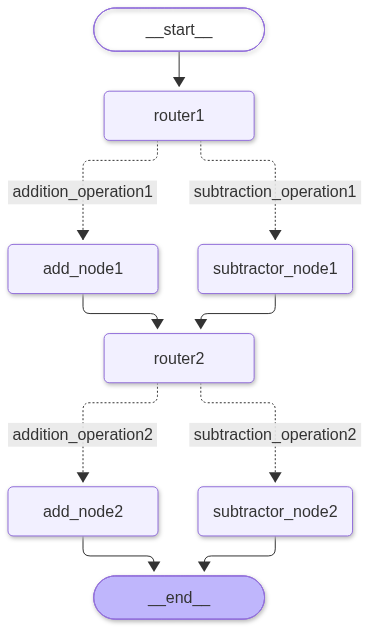

In [5]:
import IPython
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [6]:
initial_state = AgentState(number1 = 10, operation1="-",number2=5, number3 = 7, operation2="+", number4=2)
print(app.invoke(initial_state))

{'number1': 10, 'operation1': '-', 'number2': 5, 'finalNumber1': 5, 'number3': 7, 'operation2': '+', 'number4': 2, 'finalNumber2': 9}
